# 06 · Model comparison and statistical tests

**Question:** which model forecasts next-day realized volatility best across 95 NSE stocks, and does
the answer depend on liquidity and market conditions?

| Model | Information used | Type |
|---|---|---|
| HAR-RV | daily / weekly / monthly RV | linear, levels, per stock |
| log-HAR | same, in logs | linear, logs, per stock |
| **HAR-RV-LSTM** | same three RV components over 22 days | non-linear, pooled |
| EGARCH-LSTM | EGARCH volatility and shock from daily returns | non-linear, pooled |
| HAR-EGARCH-LSTM | both (ablation) | non-linear, pooled |

All models are scored on the **same** stock-days. The test period (Jan 2025 – Apr 2026) was never
used for fitting, early stopping or design choices. QLIKE is the main loss.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from volforecast import config as C
from volforecast import evaluation as ev
from volforecast.plotting import set_style, save, MODEL_COLORS, GROUP_COLORS

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.5g}")
MAIN = ["HAR-RV", "log-HAR", "HAR-RV-LSTM", "EGARCH-LSTM"]
ALL = MAIN + ["HAR-EGARCH-LSTM"]
GROUPS = ["High Liquidity", "Medium Liquidity", "Low Liquidity"]

## 1. Load and align forecasts

In [2]:
liq = pd.read_csv(C.PROCESSED_DIR / "liquidity_groups.csv")
panel = pd.read_parquet(C.PROCESSED_DIR / "daily_panel.parquet", columns=["Symbol", "Date", "RV_22"])
files = {"har": "har", "HAR-RV-LSTM": "har_rv_lstm", "EGARCH-LSTM": "egarch_lstm",
         "HAR-EGARCH-LSTM": "har_egarch_lstm"}

def load(split):
    base = pd.read_csv(C.FORECAST_DIR / f"har_{split}_forecasts.csv", parse_dates=["Date", "Date_t1"])
    for name, slug in list(files.items())[1:]:
        f = pd.read_csv(C.FORECAST_DIR / f"{slug}_{split}_forecasts.csv", parse_dates=["Date", "Date_t1"])
        f = f.rename(columns={C.TARGET: f"{C.TARGET}_{name}"}).drop(columns=["Date_t1"])
        base = base.merge(f, on=["Symbol", "Date"], how="inner", validate="one_to_one")
        gap = (base[C.TARGET] - base[f"{C.TARGET}_{name}"]).abs().max()
        assert gap < 1e-9, f"target mismatch for {name}"
        base = base.drop(columns=f"{C.TARGET}_{name}")
    base = base.merge(liq[["Symbol", "Liquidity_Group", "Liquidity_Rank"]], on="Symbol")
    return base.merge(panel, on=["Symbol", "Date"], how="left").sort_values(["Date", "Symbol"])

valid, test = load("valid"), load("test")
print(f"Validation: {len(valid):,} stock-days | Test: {len(test):,} stock-days, "
      f"{test.Symbol.nunique()} stocks, {test.Date_t1.min().date()} to {test.Date_t1.max().date()}")

Validation: 46,599 stock-days | Test: 29,774 stock-days, 95 stocks, 2025-01-01 to 2026-04-09


## 2. Overall accuracy

In [3]:
val_tab = ev.metric_table(valid, ALL)
test_tab = ev.metric_table(test, ALL)
for t in (val_tab, test_tab):
    t["QLIKE vs HAR-RV (%)"] = 100 * (t["QLIKE"] / t.loc["HAR-RV", "QLIKE"] - 1)
    t["QLIKE vs log-HAR (%)"] = 100 * (t["QLIKE"] / t.loc["log-HAR", "QLIKE"] - 1)
print("VALIDATION (used for early stopping)"); display(val_tab)
print("TEST (out-of-sample)"); display(test_tab)
val_tab.to_csv(C.TABLE_DIR / "overall_validation_metrics.csv")
test_tab.to_csv(C.TABLE_DIR / "overall_test_metrics.csv")

VALIDATION (used for early stopping)


,Obs,MSE,MAE,QLIKE,QLIKE vs HAR-RV (%),QLIKE vs log-HAR (%)
Model,,,,,,
HAR-RV,46599,5.9327e-07,0.00022327,0.26058,0,13.372
log-HAR,46599,6.0158e-07,0.00019695,0.22985,-11.795,0
HAR-RV-LSTM,46599,6.047e-07,0.00019244,0.22577,-13.358,-1.7723
EGARCH-LSTM,46599,5.7105e-07,0.00022506,0.27027,3.7178,17.587
HAR-EGARCH-LSTM,46599,5.1612e-07,0.00018917,0.21836,-16.202,-4.9966


TEST (out-of-sample)


,Obs,MSE,MAE,QLIKE,QLIKE vs HAR-RV (%),QLIKE vs log-HAR (%)
Model,,,,,,
HAR-RV,29774,9.3025e-08,0.00016561,0.2286,0,16.31
log-HAR,29774,8.5974e-08,0.00014315,0.19655,-14.023,0
HAR-RV-LSTM,29774,8.5427e-08,0.00014013,0.19345,-15.375,-1.5726
EGARCH-LSTM,29774,1.1856e-07,0.00020344,0.27085,18.482,37.807
HAR-EGARCH-LSTM,29774,8.703e-08,0.00014436,0.19311,-15.527,-1.7497


### Seed stability of the LSTMs
Each LSTM was trained with three random seeds. A gain is only meaningful if it is larger than the
spread between seeds.

In [4]:
seed_rows = []
for m in ["HAR-RV-LSTM", "EGARCH-LSTM", "HAR-EGARCH-LSTM"]:
    cols = [c for c in test if c.startswith(m + "_seed")]
    q = [ev.losses(test[C.TARGET], test[c])["QLIKE"].mean() for c in cols]
    qv = [ev.losses(valid[C.TARGET], valid[c])["QLIKE"].mean() for c in cols]
    seed_rows.append({"Model": m, "Valid QLIKE mean": np.mean(qv), "Valid QLIKE sd": np.std(qv, ddof=1),
                      "Test QLIKE mean": np.mean(q), "Test QLIKE sd": np.std(q, ddof=1),
                      "Test min": np.min(q), "Test max": np.max(q),
                      "Ensemble test QLIKE": test_tab.loc[m, "QLIKE"]})
seeds = pd.DataFrame(seed_rows).set_index("Model")
seeds.to_csv(C.TABLE_DIR / "lstm_seed_stability.csv")
seeds

,Valid QLIKE mean,Valid QLIKE sd,Test QLIKE mean,Test QLIKE sd,Test min,Test max,Ensemble test QLIKE
Model,,,,,,,
HAR-RV-LSTM,0.22642,0.00028003,0.19396,0.0017297,0.19264,0.19592,0.19345
EGARCH-LSTM,0.27085,0.0011117,0.27126,0.00086122,0.27032,0.27202,0.27085
HAR-EGARCH-LSTM,0.21885,0.00062284,0.19347,0.0016673,0.19156,0.19462,0.19311


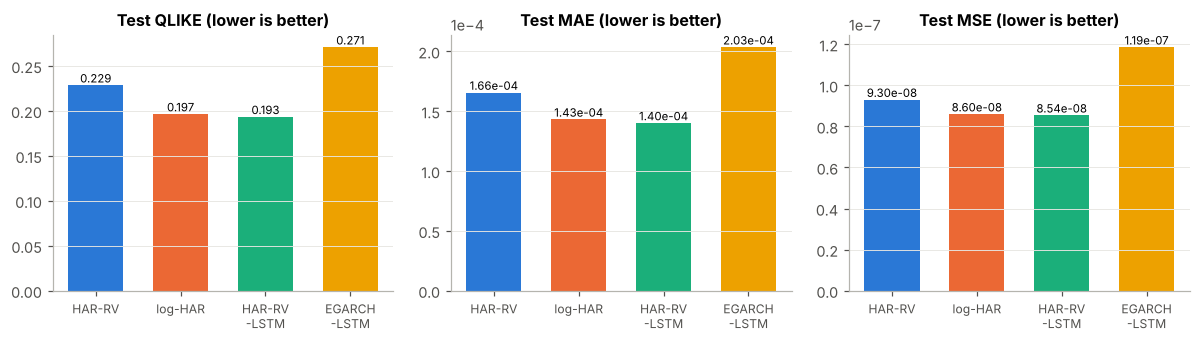

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, metric in zip(axes, ["QLIKE", "MAE", "MSE"]):
    vals = test_tab.loc[MAIN, metric]
    ax.bar(range(len(MAIN)), vals, color=[MODEL_COLORS[m] for m in MAIN], width=0.65)
    ax.set_xticks(range(len(MAIN)), [m.replace("-LSTM", "\n-LSTM") for m in MAIN], fontsize=8)
    ax.set_title(f"Test {metric} (lower is better)")
    for i, v in enumerate(vals):
        ax.text(i, v, f"{v:.3f}" if metric == "QLIKE" else f"{v:.2e}", ha="center", va="bottom", fontsize=7.5)
    ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 3))
fig.tight_layout()
save(fig, "fig_test_losses"); plt.show()

## 3. Are the differences statistically significant?
Panel Diebold–Mariano test: the loss difference (A − B) is averaged across stocks each day and
its mean is tested with Newey–West (5 lags) standard errors. Positive = model B is better.
Holm-adjusted p-values control for running several tests per loss.

In [6]:
pairs = [("HAR-RV", "log-HAR"), ("HAR-RV", "HAR-RV-LSTM"), ("log-HAR", "HAR-RV-LSTM"),
         ("HAR-RV", "EGARCH-LSTM"), ("log-HAR", "EGARCH-LSTM"), ("EGARCH-LSTM", "HAR-RV-LSTM"),
         ("HAR-RV-LSTM", "HAR-EGARCH-LSTM")]
dm = ev.dm_table(test, pairs)
dm.to_csv(C.TABLE_DIR / "dm_tests_test.csv", index=False)
dm

,Metric,Model A,Model B,Mean diff (A-B),t-stat,p-value,Days,Holm p
0,QLIKE,HAR-RV,log-HAR,0.032014,6.539,6.1918e-11,314,2.4767e-10
1,QLIKE,HAR-RV,HAR-RV-LSTM,0.035091,6.1848,6.2194e-10,314,1.8658e-09
2,QLIKE,log-HAR,HAR-RV-LSTM,0.0030763,2.8015,0.0050861,314,0.010172
3,QLIKE,HAR-RV,EGARCH-LSTM,-0.04248,-12.733,3.8767e-37,314,2.7137e-36
4,QLIKE,log-HAR,EGARCH-LSTM,-0.074494,-10.394,2.6399e-25,314,1.5839e-24
5,QLIKE,EGARCH-LSTM,HAR-RV-LSTM,0.077571,9.8919,4.5133e-23,314,2.2567e-22
6,QLIKE,HAR-RV-LSTM,HAR-EGARCH-LSTM,0.00027319,0.24008,0.81027,314,0.81027
7,MSE,HAR-RV,log-HAR,7.0477e-09,7.4896,6.909e-14,314,2.7636e-13
8,MSE,HAR-RV,HAR-RV-LSTM,7.5901e-09,7.8489,4.1977e-15,314,2.0988e-14
9,MSE,log-HAR,HAR-RV-LSTM,5.4242e-10,1.2807,0.2003,314,0.25618


In [7]:
boot = pd.DataFrame([ev.block_bootstrap(test, a, b) for a, b in pairs])
boot.to_csv(C.TABLE_DIR / "block_bootstrap_qlike.csv", index=False)
boot

,Model A,Model B,Mean diff (A-B),CI 2.5%,CI 97.5%
0,HAR-RV,log-HAR,0.032014,0.02349,0.041707
1,HAR-RV,HAR-RV-LSTM,0.035091,0.024971,0.046467
2,log-HAR,HAR-RV-LSTM,0.0030763,0.0010546,0.0053767
3,HAR-RV,EGARCH-LSTM,-0.04248,-0.048338,-0.035872
4,log-HAR,EGARCH-LSTM,-0.074494,-0.088489,-0.061063
5,EGARCH-LSTM,HAR-RV-LSTM,0.077571,0.063131,0.092917
6,HAR-RV-LSTM,HAR-EGARCH-LSTM,0.00027319,-0.0015504,0.0027323


## 4. When does the LSTM gain arise? Cumulative loss difference through the test period
A line that rises steadily means the gain is spread across the whole period, not a few days.

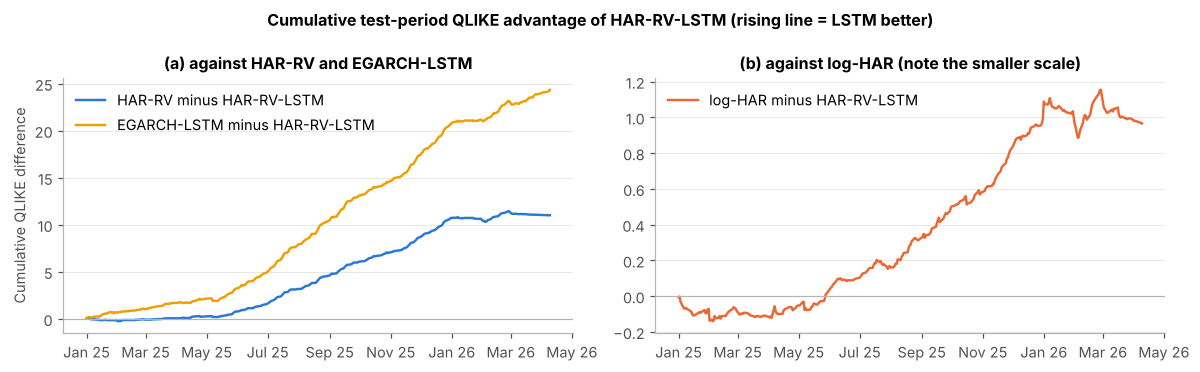

In [8]:
def daily_diff(df, a, b):
    l = ev.losses(df[C.TARGET], df[a])["QLIKE"] - ev.losses(df[C.TARGET], df[b])["QLIKE"]
    return pd.Series(l, index=df["Date_t1"].to_numpy()).groupby(level=0).mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, comps, title in [
        (axes[0], [("HAR-RV", MODEL_COLORS["HAR-RV"]), ("EGARCH-LSTM", MODEL_COLORS["EGARCH-LSTM"])],
         "(a) against HAR-RV and EGARCH-LSTM"),
        (axes[1], [("log-HAR", MODEL_COLORS["log-HAR"])], "(b) against log-HAR (note the smaller scale)")]:
    for a, col in comps:
        s = daily_diff(test, a, "HAR-RV-LSTM").cumsum()
        ax.plot(s.index, s, color=col, label=f"{a} minus HAR-RV-LSTM")
    ax.axhline(0, color="#b5b4ae", lw=0.8)
    ax.set_title(title)
    ax.legend(loc="upper left")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes[0].set_ylabel("Cumulative QLIKE difference")
fig.suptitle("Cumulative test-period QLIKE advantage of HAR-RV-LSTM (rising line = LSTM better)",
             fontweight="bold", fontsize=10.5)
fig.tight_layout()
save(fig, "fig_cumulative_qlike"); plt.show()

## 5. Liquidity groups (the core research question)
H1: a flexible model gains most in noisy, illiquid stocks. H2: it gains most in liquid stocks,
where RV is a cleaner target. Groups were formed on training-period liquidity only.

In [9]:
liq_tab = ev.grouped_metrics(test, ALL, "Liquidity_Group")
liq_q = liq_tab.pivot(index="Liquidity_Group", columns="Model", values="QLIKE").loc[GROUPS, ALL]
gain = pd.DataFrame({
    "LSTM vs HAR-RV (%)": 100 * (liq_q["HAR-RV-LSTM"] / liq_q["HAR-RV"] - 1),
    "LSTM vs log-HAR (%)": 100 * (liq_q["HAR-RV-LSTM"] / liq_q["log-HAR"] - 1),
})
dm_g = []
for g in GROUPS:
    d = test[test.Liquidity_Group == g]
    for a in ["HAR-RV", "log-HAR"]:
        r = ev.dm_test(d, a, "HAR-RV-LSTM")
        dm_g.append({"Liquidity_Group": g, "Benchmark": a, "t-stat": r["t-stat"], "p-value": r["p-value"]})
dm_g = pd.DataFrame(dm_g)
liq_tab.to_csv(C.TABLE_DIR / "liquidity_group_metrics.csv", index=False)
dm_g.to_csv(C.TABLE_DIR / "liquidity_group_dm.csv", index=False)
display(liq_q); display(gain); display(dm_g)

Model,HAR-RV,log-HAR,HAR-RV-LSTM,EGARCH-LSTM,HAR-EGARCH-LSTM
Liquidity_Group,,,,,
High Liquidity,0.22599,0.19201,0.19148,0.24775,0.19
Medium Liquidity,0.21921,0.19249,0.18984,0.25559,0.18969
Low Liquidity,0.2403,0.205,0.19892,0.30873,0.19952


,LSTM vs HAR-RV (%),LSTM vs log-HAR (%)
Liquidity_Group,,
High Liquidity,-15.27,-0.27466
Medium Liquidity,-13.397,-1.3736
Low Liquidity,-17.221,-2.9684


,Liquidity_Group,Benchmark,t-stat,p-value
0,High Liquidity,HAR-RV,5.4433,5.229e-08
1,High Liquidity,log-HAR,0.38483,0.70037
2,Medium Liquidity,HAR-RV,5.604,2.0947e-08
3,Medium Liquidity,log-HAR,2.4341,0.01493
4,Low Liquidity,HAR-RV,6.6529,2.8737e-11
5,Low Liquidity,log-HAR,3.9559,7.6245e-05


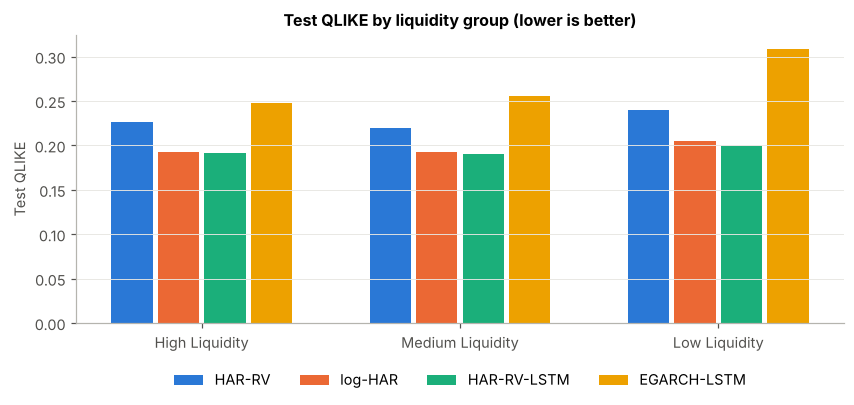

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.4))
w = 0.18
for i, m in enumerate(MAIN):
    ax.bar(np.arange(3) + (i - 1.5) * w, liq_q[m], width=w - 0.02, color=MODEL_COLORS[m], label=m)
ax.set_xticks(range(3), GROUPS)
ax.set_ylabel("Test QLIKE")
ax.set_title("Test QLIKE by liquidity group (lower is better)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
save(fig, "fig_liquidity_qlike"); plt.show()

### Stock by stock
Share of stocks on which each model beats the benchmark, and the per-stock gain against liquidity rank.

In [11]:
win_h, per_stock = ev.stock_win_rates(test, ["log-HAR", "HAR-RV-LSTM", "EGARCH-LSTM"], "HAR-RV")
win_l, _ = ev.stock_win_rates(test, ["HAR-RV-LSTM", "EGARCH-LSTM"], "log-HAR")
wins = pd.concat([win_h, win_l], axis=1)
per_stock = per_stock.join(liq.set_index("Symbol")[["Liquidity_Rank", "Liquidity_Group"]])
per_stock["gain_vs_logHAR_pct"] = 100 * (1 - per_stock["HAR-RV-LSTM"] / per_stock["log-HAR"])
per_stock.to_csv(C.TABLE_DIR / "per_stock_test_qlike.csv")
rho = per_stock[["gain_vs_logHAR_pct", "Liquidity_Rank"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman(gain vs log-HAR, liquidity rank) = {rho:.2f}")
wins

Spearman(gain vs log-HAR, liquidity rank) = 0.29


,share beating HAR-RV,share beating log-HAR
log-HAR,1,NaN
HAR-RV-LSTM,1,0.70526
EGARCH-LSTM,0.14737,0


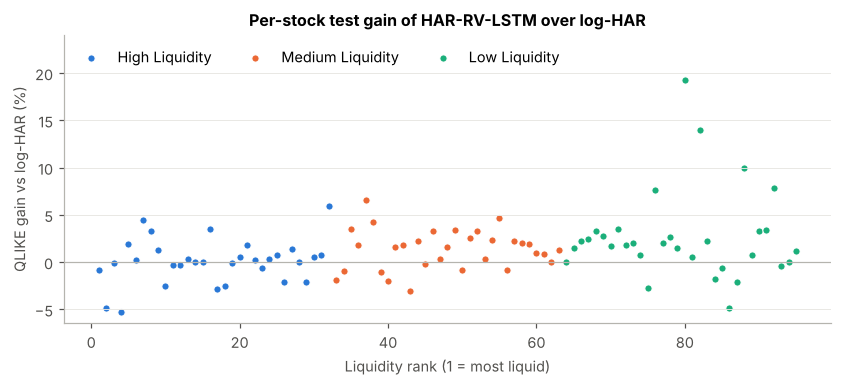

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for g in GROUPS:
    s = per_stock[per_stock.Liquidity_Group == g]
    ax.scatter(s["Liquidity_Rank"], s["gain_vs_logHAR_pct"], s=22, color=GROUP_COLORS[g], label=g,
               edgecolor="white", linewidth=0.6)
ax.axhline(0, color="#b5b4ae", lw=0.8)
ax.set_xlabel("Liquidity rank (1 = most liquid)")
ax.set_ylabel("QLIKE gain vs log-HAR (%)")
ax.set_title("Per-stock test gain of HAR-RV-LSTM over log-HAR")
ax.legend(ncol=3, loc="upper left")
ax.set_ylim(top=per_stock["gain_vs_logHAR_pct"].max() * 1.25)
save(fig, "fig_per_stock_gain"); plt.show()

## 6. Market regimes
**Ex-ante regime (usable in real time):** the market's average monthly RV (RV₂₂ averaged across stocks on
day *t*) is classed Calm / Normal / Turbulent using terciles from the **training** period.
**Ex-post regime (descriptive):** the realized RV of the target day, cut at test terciles.

In [13]:
mkt = (pd.read_parquet(C.PROCESSED_DIR / "daily_panel.parquet", columns=["Symbol", "Date", "RV_22"])
       .groupby("Date")["RV_22"].mean())
cuts = mkt[(mkt.index >= C.TRAIN_START) & (mkt.index <= C.TRAIN_END)].quantile([1 / 3, 2 / 3]).to_numpy()
lab = ["Calm", "Normal", "Turbulent"]
test["Regime_ex_ante"] = pd.cut(test["Date"].map(mkt), [-np.inf, *cuts, np.inf], labels=lab)
q = test[C.TARGET].quantile([1 / 3, 2 / 3]).to_numpy()
test["Regime_ex_post"] = pd.cut(test[C.TARGET], [-np.inf, *q, np.inf], labels=["Low RV", "Medium RV", "High RV"])
reg_a = ev.grouped_metrics(test, MAIN, "Regime_ex_ante").pivot(index="Regime_ex_ante", columns="Model", values="QLIKE")[MAIN]
reg_a["Days"] = test.groupby("Regime_ex_ante", observed=True)["Date"].nunique()
reg_p = ev.grouped_metrics(test, MAIN, "Regime_ex_post").pivot(index="Regime_ex_post", columns="Model", values="QLIKE")[MAIN]
reg_a.to_csv(C.TABLE_DIR / "regime_ex_ante_qlike.csv"); reg_p.to_csv(C.TABLE_DIR / "regime_ex_post_qlike.csv")
display(reg_a); display(reg_p)

Model,HAR-RV,log-HAR,HAR-RV-LSTM,EGARCH-LSTM,Days
Regime_ex_ante,,,,,
Calm,0.23441,0.19706,0.19358,0.28253,253
Normal,0.20426,0.19437,0.19293,0.22197,61


Model,HAR-RV,log-HAR,HAR-RV-LSTM,EGARCH-LSTM
Regime_ex_post,,,,
High RV,0.24174,0.28103,0.29198,0.26688
Low RV,0.30959,0.20434,0.19126,0.36424
Medium RV,0.13446,0.10426,0.097119,0.18143


## 7. Robustness: sub-periods, extreme days, bias

In [14]:
dates = np.array(sorted(test["Date_t1"].unique()))
test["Subperiod"] = test["Date_t1"].map({d: f"P{i + 1}" for i, ch in enumerate(np.array_split(dates, 4)) for d in ch})
sub = ev.grouped_metrics(test, MAIN, "Subperiod").pivot(index="Subperiod", columns="Model", values="QLIKE")[MAIN]
sub["From"] = test.groupby("Subperiod")["Date_t1"].min().dt.date
sub["To"] = test.groupby("Subperiod")["Date_t1"].max().dt.date
sub.to_csv(C.TABLE_DIR / "subperiod_qlike.csv")
display(sub)

trim = ev.metric_table(test[test[C.TARGET] <= test[C.TARGET].quantile(0.99)], MAIN)
trim.to_csv(C.TABLE_DIR / "trimmed_top1pct_metrics.csv")
display(trim)

Model,HAR-RV,log-HAR,HAR-RV-LSTM,EGARCH-LSTM,From,To
Subperiod,,,,,,
P1,0.20482,0.20096,0.20178,0.22826,2025-01-01,2025-04-28
P2,0.22457,0.18188,0.17762,0.26833,2025-04-29,2025-08-19
P3,0.25036,0.18906,0.18109,0.30028,2025-08-20,2025-12-12
P4,0.23506,0.21455,0.21358,0.28725,2025-12-15,2026-04-09


,Obs,MSE,MAE,QLIKE
Model,,,,
HAR-RV,29476,4.5382e-08,0.00014905,0.2053
log-HAR,29476,3.7312e-08,0.00012618,0.17015
HAR-RV-LSTM,29476,3.6783e-08,0.00012305,0.16618
EGARCH-LSTM,29476,7.6123e-08,0.00018857,0.25067


**Mincer–Zarnowitz regression** (in logs): $\log RV_{t+1} = \alpha + \beta \log \hat h_{t+1}$.
A well-calibrated forecast has β close to 1; R² measures how much of the day-to-day variation it explains.
Standard errors are clustered by date.

In [15]:
mz = ev.mincer_zarnowitz(test, MAIN)
mz["Mean forecast / mean RV"] = [test[m].mean() / test[C.TARGET].mean() for m in MAIN]
mz.to_csv(C.TABLE_DIR / "mincer_zarnowitz_test.csv")
mz

,alpha,beta,se(beta),R2,Mean forecast / mean RV
Model,,,,,
HAR-RV,-0.81453,0.94847,0.017226,0.40217,1.2095
log-HAR,-0.93106,0.91805,0.016814,0.46249,1.0803
HAR-RV-LSTM,-0.77487,0.93443,0.017866,0.47003,1.0591
EGARCH-LSTM,-2.1926,0.78975,0.013749,0.34769,1.3949


## 8. Forecasts against realized volatility

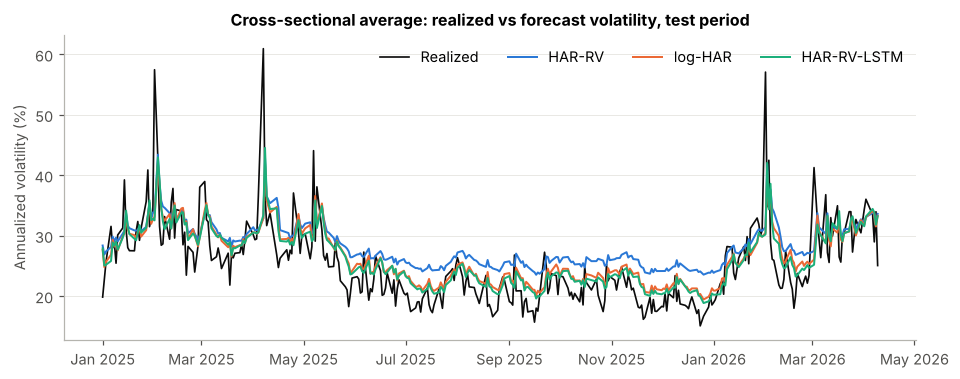

In [16]:
avg = test.groupby("Date_t1")[[C.TARGET] + MAIN].mean()
vol = np.sqrt(252 * avg) * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(vol.index, vol[C.TARGET], color=MODEL_COLORS["Actual RV"], lw=1.1, label="Realized")
for m in ["HAR-RV", "log-HAR", "HAR-RV-LSTM"]:
    ax.plot(vol.index, vol[m], color=MODEL_COLORS[m], lw=1.3, label=m)
ax.set_ylabel("Annualized volatility (%)")
ax.set_title("Cross-sectional average: realized vs forecast volatility, test period")
ax.legend(ncol=4, loc="upper right")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
save(fig, "fig_forecast_vs_actual"); plt.show()

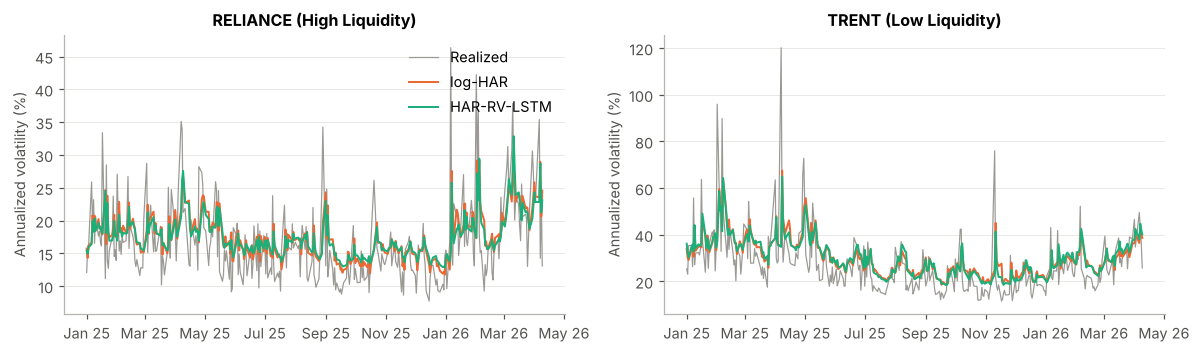

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3), sharey=False)
for ax, sym in zip(axes, ["RELIANCE", "TRENT"]):
    d = test[test.Symbol == sym].set_index("Date_t1")
    ax.plot(d.index, np.sqrt(252 * d[C.TARGET]) * 100, color="#9a9994", lw=0.8, label="Realized")
    for m in ["log-HAR", "HAR-RV-LSTM"]:
        ax.plot(d.index, np.sqrt(252 * d[m]) * 100, color=MODEL_COLORS[m], lw=1.3, label=m)
    g = d["Liquidity_Group"].iloc[0]
    ax.set_title(f"{sym} ({g})")
    ax.set_ylabel("Annualized volatility (%)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes[0].legend(loc="upper right")
fig.tight_layout()
save(fig, "fig_example_stocks"); plt.show()

## 9. Training curves

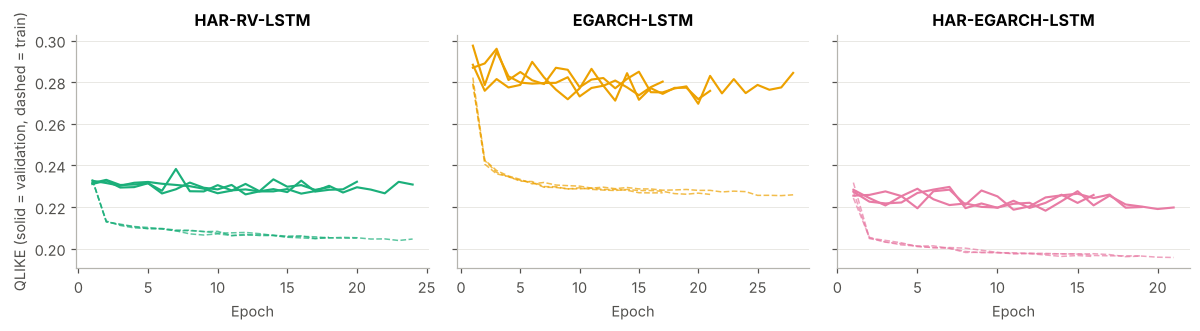

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.1), sharey=True)
for ax, m in zip(axes, ["HAR-RV-LSTM", "EGARCH-LSTM", "HAR-EGARCH-LSTM"]):
    h = pd.read_csv(C.TABLE_DIR / f"{m.lower().replace('-', '_')}_training_history.csv")
    for seed, s in h.groupby("Seed"):
        ax.plot(s["Epoch"], s["Train_QLIKE"], color=MODEL_COLORS[m], lw=1, ls="--", alpha=0.7)
        ax.plot(s["Epoch"], s["Validation_QLIKE"], color=MODEL_COLORS[m], lw=1.4)
    ax.set_title(m)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("QLIKE (solid = validation, dashed = train)")
fig.tight_layout()
save(fig, "fig_training_curves"); plt.show()

## 10. Key numbers for the paper

In [19]:
key = {
    "test_obs": int(len(test)), "test_stocks": int(test.Symbol.nunique()),
    "test_days": int(test.Date_t1.nunique()), "valid_obs": int(len(valid)),
    "test_qlike": test_tab["QLIKE"].round(4).to_dict(),
    "valid_qlike": val_tab["QLIKE"].round(4).to_dict(),
    "win_rates": wins.round(3).to_dict(),
    "spearman_gain_liquidity": round(float(rho), 3),
}
json.dump(key, open(C.TABLE_DIR / "key_numbers.json", "w"), indent=1, default=str)
key

{'test_obs': 29774,
 'test_stocks': 95,
 'test_days': 314,
 'valid_obs': 46599,
 'test_qlike': {'HAR-RV': 0.2286,
  'log-HAR': 0.1965,
  'HAR-RV-LSTM': 0.1935,
  'EGARCH-LSTM': 0.2709,
  'HAR-EGARCH-LSTM': 0.1931},
 'valid_qlike': {'HAR-RV': 0.2606,
  'log-HAR': 0.2298,
  'HAR-RV-LSTM': 0.2258,
  'EGARCH-LSTM': 0.2703,
  'HAR-EGARCH-LSTM': 0.2184},
 'win_rates': {'share beating HAR-RV': {'log-HAR': 1.0,
   'HAR-RV-LSTM': 1.0,
   'EGARCH-LSTM': 0.147},
  'share beating log-HAR': {'log-HAR': nan,
   'HAR-RV-LSTM': 0.705,
   'EGARCH-LSTM': 0.0}},
 'spearman_gain_liquidity': 0.295}